# Baseline de la cátedra (diapositiva) con el código de la plantilla z495
Mismo código y mismo orden de celdas que la plantilla de la cátedra (Tarea para el Hogar 04: `mlr3mbo`, `particionar`, `loguear`). Todo lo demás sigue la diapositiva *Baseline*:

| Diapositiva | Cómo queda en esta notebook |
|---|---|
| 762 columnas para entrenar | Se imprime la cantidad real antes de la optimización |
| Data quality | En cada `foto_mes`, variable con todos los valores en cero y sin NA pasa a NA |
| FE histórico | lag1, lag2, delta1 y delta2 de todas las variables menos `numero_de_cliente`, `foto_mes` y `clase_ternaria` |
| Búsqueda | `semilla_primigenia` 585581, `ksemillerio` 1, `repe` 1, `iteraciones` 10, `undersampling` 0,1, `training_pct` 70 |
| Fijos | `min_data_in_leaf` 0, `feature_fraction` 0,5, `feature_fraction_bynode` 0,2, `learning_rate` 0,005 |
| Bordes | `num_iterations` 64–4096, `num_leaves` 16–2048, `min_sum_hessian_in_leaf` 1e-6–0,1 |
| Producción | Entrena con 202103+202104, predice 202106, **10 semillas**, `undersampling` 0,1 |
| A reportar | AUC, mejores hiperparámetros, ganancia máxima y cantidad de envíos |

**Cambios respecto de z495 (todos para respetar la diapositiva):**
- Sin Salsa Mágica: no se sacan `cprestamos_personales` ni `mprestamos_personales`.
- Se entrena con 202103 y 202104 (la plantilla usaba solo 202104) y se agregan data quality y lags/deltas.
- Se agrega `feature_fraction_bynode` = 0,2 a los parámetros fijos.
- La validación es el 30 % limpio (`fold == 2`, ~97.800 filas) y no `training == 0`: este último incluye también los CONTINUA que el undersampling descartó del 70 % de entrenamiento (~300.900 filas).
- La métrica de la búsqueda es `auc` (la plantilla usaba `average_precision`).
- La plantilla pedía `n_evals = 10`, pero el diseño inicial de `mlr3mbo` ya evalúa 12 configuraciones y la búsqueda terminaba ahí, sin ninguna iteración bayesiana. Acá el terminador es 12 + 10 = 22 evaluaciones y se imprime cuántas se hicieron.
- Producción con 10 semillas (se promedian las probabilidades). Las semillas son 10 primos sorteados a partir de la semilla primigenia.
- Corre en local (sin Colab ni Drive).
- Si ya existe `BO_log.txt` en la carpeta del experimento, se archiva con fecha y hora antes de la BO, y producción verifica que el log tenga solo las 22 evaluaciones de esta corrida.

**Memoria:** los lags sobre 202103, 202104 y 202106 ocupan varios GB. Cerrá los otros kernels antes de correr.

## 1. Seteo del ambiente local

In [1]:
# instala solo lo que falta (la primera vez puede tardar)
paquetes <- c("data.table", "R.utils", "rlist", "bbotk", "mlr3", "mlr3mbo", "mlr3learners", "DiceKriging", "lightgbm")
faltan <- paquetes[!sapply(paquetes, requireNamespace, quietly = TRUE)]
if (length(faltan) > 0) install.packages(faltan)

In [2]:
# limpio la memoria
rm(list = ls(all.names = TRUE)) # remove all objects
gc(full = TRUE, verbose = FALSE) # garbage collection

library(data.table)
library(R.utils)
library(rlist)
library(bbotk)
library(mlr3)
library(mlr3mbo)
library(mlr3learners)
# library(paradox)
library(DiceKriging)
library(lightgbm)

RNGkind("L'Ecuyer-CMRG") # generador de la plantilla, fijo para todo el script
options(scipen = 999)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2260766,120.8,4465342,238.5,3070674,164.0
Vcells,3691425,28.2,8388608,64.0,8339283,63.7



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Loading required package: paradox


Attaching package: ‘ml

In [3]:
t_inicio_total <- Sys.time()
tiempos <- list()
marcar_tiempo <- function(etapa, t_desde) {
  dt <- as.numeric(difftime(Sys.time(), t_desde, units = "mins"))
  tiempos[[etapa]] <<- dt
  cat(sprintf("[tiempo] %s: %.1f min\n", etapa, dt))
  invisible(Sys.time())
}


## 2. Definicion de Parametros

### 2.1 Leemos .yaml

In [4]:
getwd()                    # ¿en qué carpeta está R?
list.files()               # ¿aparece config.yaml aquí?
file.exists("config.yaml") # TRUE o FALSE

[1] "/home/ds/notebook"

[1] "BASELINE_FINAL.ipynb" "config.yaml"

[1] TRUE

In [5]:
# Leer el archivo de configuración.
config <- yaml::read_yaml("config.yaml",  eval.expr = TRUE)

In [6]:
PARAM <- list()
#directorios
# PARAM$data_dir <- config$directorios$datasets
# PARAM$exp_dir  <- config$directorios$exp

# LEEMOS DIRECCIONES RELATIVAS Y HACEMOS ABOLUTAS PARA EVITAR PROBLEMAS CON LOS "setwd()" en adelante.
PARAM$data_dir <- normalizePath(
  config$directorios$datasets, mustWork = TRUE
)
PARAM$exp_dir <- normalizePath(
  config$directorios$exp, mustWork = TRUE
)

# training y future
PARAM$semillas <- config$training$semillas
PARAM$semilla_primigenia <- config$training$semilla_primigenia
PARAM$training_pct <- config$training$training_pct
PARAM$train <- config$training$train
PARAM$train_final <- config$training$train_final
PARAM$future <-  config$training$future
PARAM$cortes <- config$training$cortes 
PARAM$trainingstrategy$undersampling <- config$training$undersampling

# diapositiva: ksemillerio 1, repe 1, iteraciones 10
PARAM$hyperparametertuning$ksemillerio <- config$bayesian$ksemillerio    # con 1 y 1 hay una sola particion y una sola semilla en la busqueda
PARAM$hyperparametertuning$repe <- config$bayesian$repe
PARAM$hyperparametertuning$iteraciones <-config$bayesian$iteraciones      # iteraciones bayesianas
PARAM$hyperparametertuning$init <- config$bayesian$init                   # diseno inicial de mlr3mbo (4 x 3 hiperparametros), no cuenta como iteracion


In [7]:
# chequeamos q existan directorios
if (!dir.exists(PARAM$data_dir)) {
  stop("No existe el directorio de datasets: ", PARAM$data_dir)
}

if (!dir.exists(PARAM$exp_dir)) {
  stop("No existe el directorio de experimentos: ", PARAM$exp_dir)
}

### 2.2 Parametros manuales

In [8]:
PARAM$experimento <-config$bayesian$exp_name

In [9]:
PARAM$experimento

[1] "20261110-avg-historico"

In [10]:
# diapositiva: produccion con 10 semillas
PARAM$semillas_finales_n <- config$training$semillas_finales  

In [11]:
# Parametros LightGBM

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <- config$lgbm$fijos

Aqui se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization

In [12]:
# # Aqui se cargan los bordes de los hiperparametros de la BO

# # SEGUN BASELINE
# PARAM$hypeparametertuning$hs <- ps(
#   num_iterations = p_int(lower = 64L, upper = 4096L),
#   num_leaves = p_int(lower = 16L, upper = 2048L),
#   min_sum_hessian_in_leaf = p_dbl(lower = 1e-06, upper = 0.1)
# )
# PARAM$hypeparametertuning$hs

In [13]:
# Aqui se cargan los bordes de los hiperparametros de la BO

# Construir el espacio usando todas las entradas de bayesian$hs.
PARAM$hypeparametertuning$hs <- do.call(
  paradox::ps,
  config$lgbm$hs
)
# PARAM$hypeparametertuning$hs2 

In [14]:
# particionar agrega una columna llamada fold a un dataset
#   que consiste en una particion estratificada segun agrupa
# particionar( data=dataset, division=c(70,30),
#  agrupa=clase_ternaria, seed=semilla)   crea una particion 70, 30

particionar <- function(data, division, agrupa = "", campo = "fold", start = 1, seed = NA) {
  if (!is.na(seed)) set.seed(seed, "L'Ecuyer-CMRG")

  bloque <- unlist(mapply(
    function(x, y) {rep(y, x)}, division, seq(from = start, length.out = length(division))))

  data[, (campo) := sample(rep(bloque, ceiling(.N / length(bloque))))[1:.N], by = agrupa]
}

In [15]:
# logueo al archivo BO_log.txt
loguear <- function(preg, arch = NA, verbose = TRUE)
{
  t0 <- Sys.time()
  reg <- copy(preg)
  if ("feature_contri" %in% names(reg)) {
    reg$feature_contri <- reg$feature_contri[1]
  }
  archivo <- arch
  if (is.na(arch)) archivo <- paste0(folder, substitute(reg), ext)


  if (!file.exists(archivo))
  {
    # Escribo los titulos
    linea <- paste0("fecha\t",
                    paste(list.names(reg), collapse = "\t"), "\n")

    cat(linea, file = archivo)
  }

  # escribo el registro
  linea <- paste0(format(t0, "%Y%m%d.%H%M%S"), "\t",     # la fecha y hora
                  gsub(", ", "\t", toString(reg)), "\n")

  cat(linea, file = archivo, append = TRUE)  # grabo al archivo

  if (verbose) cat(linea)   # imprimo por pantalla
}

## 3. Generacion de la clase_ternaria (solo si no existe `competencia_02.csv`)

In [16]:
PARAM$data_dir

[1] "/home/ds/datasets"

In [17]:
archivo_crudo    <- file.path(PARAM$data_dir, "competencia_02_crudo.csv.gz")
archivo_ternaria <- file.path(PARAM$data_dir, "competencia_02.csv")

if (!file.exists(archivo_ternaria)) {
  if (!file.exists(archivo_crudo)) stop("No encuentro ni competencia_02.csv ni competencia_02_crudo.csv en ", PARAM$data_dir)

  dataset <- fread(archivo_crudo)

  # calculo el periodo0 consecutivo
  dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes / 100) * 12 + foto_mes %% 100)]

  # ordeno
  setorder(dsimple, numero_de_cliente, periodo0)

  # calculo topes
  periodo_ultimo <- dsimple[, max(periodo0)]
  periodo_anteultimo <- periodo_ultimo - 1

  # calculo los leads de orden 1 y 2
  dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n = 1:2, fill = NA, type = "lead"), numero_de_cliente]

  # assign most common class values = "CONTINUA"
  dsimple[periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA"]

  # calculo BAJA+1
  dsimple[periodo0 < periodo_ultimo &
    (is.na(periodo1) | periodo0 + 1 < periodo1),
    clase_ternaria := "BAJA+1"]

  # calculo BAJA+2
  dsimple[periodo0 < periodo_anteultimo & (periodo0 + 1 == periodo1)
    & (is.na(periodo2) | periodo0 + 2 < periodo2),
    clase_ternaria := "BAJA+2"]

  # pego el resultado en el dataset original y grabo
  setorder(dsimple, pos)
  dataset[, clase_ternaria := dsimple$clase_ternaria]
  fwrite(dataset, file = archivo_ternaria, sep = ",")
  rm(dataset, dsimple); gc()
}
cat("Uso:", archivo_ternaria, "\n")

Uso: /home/ds/datasets/competencia_02.csv 


In [18]:
#dataset <- fread(archivo_ternaria, stringsAsFactors = TRUE)
# sort(unique(dataset$foto_mes))

## 4. Preprocesamiento

In [19]:
# carpeta de trabajo
dir.create(file.path(PARAM$exp_dir, PARAM$experimento), showWarnings = FALSE, recursive = TRUE)
setwd(file.path(PARAM$exp_dir, PARAM$experimento))

# lectura del dataset (solo hasta el mes del future: no hace falta mas)
dataset <- fread(archivo_ternaria, stringsAsFactors = TRUE)
dataset <- dataset[foto_mes <= max(PARAM$future)]
stopifnot("clase_ternaria" %in% colnames(dataset))
setorder(dataset, numero_de_cliente, foto_mes)
cat("Meses:", paste(sort(unique(dataset$foto_mes)), collapse = ", "), "|", nrow(dataset), "filas x", ncol(dataset), "columnas\n")

Meses: 201901, 201902, 201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910, 201911, 201912, 202001, 202002, 202003, 202004, 202005, 202006, 202007, 202008, 202009, 202010, 202011, 202012, 202101, 202102, 202103, 202104, 202105, 202106 | 4378500 filas x 155 columnas


### 4.1 Data quality
En cada `foto_mes`, la variable con **todos** sus valores exactamente en cero y **ningún** NA pasa a NA (como `ccajas_depositos` en 202105).

In [20]:
# campos_excluidos <- c("numero_de_cliente", "foto_mes", "clase_ternaria")
campos_excluidos <- config$training$campos_excluidos
campos_dq <- setdiff(colnames(dataset), campos_excluidos)
campos_dq <- campos_dq[sapply(dataset[, ..campos_dq], is.numeric)]

correcciones <- list()
for (mes in sort(unique(dataset$foto_mes))) {
  filas <- which(dataset$foto_mes == mes)
  for (campo in campos_dq) {
    x <- dataset[[campo]][filas]
    if (!anyNA(x) && all(x == 0)) {
      set(dataset, i = filas, j = campo, value = NA)
      correcciones[[length(correcciones) + 1]] <- data.table(foto_mes = mes, variable = campo, filas = length(filas))
    }
  }
}
correcciones <- rbindlist(correcciones)
cat("Variables pasadas a NA por mes:", nrow(correcciones), "\n")
if (nrow(correcciones) > 0) {
  print(correcciones)
  fwrite(correcciones, "data_quality_correcciones.csv")
}

Variables pasadas a NA por mes: 95 
    foto_mes                           variable  filas
       <int>                             <char>  <int>
 1:   201904  ctarjeta_visa_debitos_automaticos 126116
 2:   201904 mttarjeta_visa_debitos_automaticos 126116
 3:   201905                      mrentabilidad 126763
 4:   201905               mrentabilidad_annual 126763
 5:   201905                        mcomisiones 126763
 6:   201905                    mactivos_margen 126763
 7:   201905                    mpasivos_margen 126763
 8:   201905                  ccomisiones_otras 126763
 9:   201905                  mcomisiones_otras 126763
10:   201910                      mrentabilidad 135633
11:   201910               mrentabilidad_annual 135633
12:   201910                        mcomisiones 135633
13:   201910                    mactivos_margen 135633
14:   201910                    mpasivos_margen 135633
15:   201910        ccajeros_propios_descuentos 135633
16:   201910        mcajeros_

### 4.2 FE histórico: lags y delta lags de orden 1 y 2

In [21]:
campos_lag <- setdiff(colnames(dataset), campos_excluidos)
campos_lag <- campos_lag[sapply(dataset[, ..campos_lag], is.numeric)]
cat("Lags y deltas para", length(campos_lag), "variables\n")

t0 <- Sys.time()
dataset[, (paste0(campos_lag, "_lag1")) := shift(.SD, n = 1, fill = NA, type = "lag"), by = numero_de_cliente, .SDcols = campos_lag]
dataset[, (paste0(campos_lag, "_lag2")) := shift(.SD, n = 2, fill = NA, type = "lag"), by = numero_de_cliente, .SDcols = campos_lag]
for (campo in campos_lag) {
  dataset[, paste0(campo, "_delta1") := get(campo) - get(paste0(campo, "_lag1"))]
  dataset[, paste0(campo, "_delta2") := get(campo) - get(paste0(campo, "_lag2"))]
}
cat("Listo en", round(as.numeric(Sys.time() - t0, units = "secs"), 1), "seg |", ncol(dataset), "columnas\n")

Lags y deltas para 152 variables
Listo en 89.4 seg | 763 columnas


In [22]:
### 4.3 FE histórico: promedio histórico sin NA

setorder(dataset, numero_de_cliente, foto_mes)  # ya está ordenado, por las dudas

avg_hist <- function(x) {
  x   <- as.numeric(x)                       # evita overflow de cumsum en enteros
  ok  <- !is.na(x)
  num <- cumsum(fifelse(ok, x, 0))           # suma solo los valores presentes
  den <- cumsum(ok)                          # cuenta solo los valores presentes
  fifelse(den > 0, num / den, NA_real_)
}

campos_avg <- campos_lag                     # las 152 originales, sin lags ni deltas
t0 <- Sys.time()
dataset[, (paste0(campos_avg, "_avg")) := lapply(.SD, avg_hist),
        by = numero_de_cliente, .SDcols = campos_avg]
cat("Listo en", round(as.numeric(Sys.time() - t0, units = "secs"), 1), "seg |",
    ncol(dataset), "columnas\n")

Listo en 174.7 seg | 915 columnas


### 4.3 Meses de training y del future
De aca en adelante no se necesitan los otros meses. Como `train_final` es igual a `train`, `dataset_train` se reutiliza en la producción y se libera `dataset` (memoria).

In [23]:
# clase01: BAJA+1 y BAJA+2 son 1, CONTINUA es 0
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+2", "BAJA+1"), 1L, 0L)]

stopifnot(identical(sort(PARAM$train), sort(PARAM$train_final)))
dataset_train <- dataset[foto_mes %in% PARAM$train]
dfuture <- dataset[foto_mes %in% PARAM$future]   # datos del futuro, para aplicar el modelo
rm(dataset); gc(full = TRUE, verbose = FALSE)

dataset_train[, .N, list(foto_mes, clase_ternaria)]

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2352614,125.7,4465342,238.5,4465342,238.5
Vcells,3023996126,23071.3,6525698891,49787.2,6170018898,47073.6


foto_mes,clase_ternaria,N
<int>,<fct>,<int>
201901,CONTINUA,122572
201902,CONTINUA,123624
201903,CONTINUA,124148
201904,CONTINUA,124765
201905,CONTINUA,125529
201906,CONTINUA,127116
201907,CONTINUA,128602
201908,CONTINUA,130573
201909,CONTINUA,132256


In [24]:
particionar(dataset_train,
  division = c(PARAM$training_pct, 100L - PARAM$training_pct),
  agrupa = "clase_ternaria",
  seed = PARAM$semilla_primigenia # aqui se usa SU semilla
)

In [25]:
# defino los datos que forma parte del training
# aqui se hace el undersampling de los CONTINUA
# notar que para esto utilizo la SEGUNDA semilla

set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset_train[, azar := runif(nrow(dataset_train))]
dataset_train[, training := 0L]

dataset_train[
  foto_mes %in% PARAM$train & fold == 1 &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

In [26]:
# los campos que se van a utilizar

campos_buenos <- setdiff(
  colnames(dataset_train),
  c("clase_ternaria", "clase01", "fold", "azar", "training")
)
cat("Columnas para entrenar:", length(campos_buenos), "(la diapositiva dice 762)\n")

Columnas para entrenar: 914 (la diapositiva dice 762)


## 5. Bayesiana
### 5.1 Configuracion Bayesian Optimization

In [27]:
# Cada corrida de la BO arranca con un log limpio:
# si ya existe BO_log.txt, se archiva con fecha y hora en el nombre
giter <- 0

if (file.exists("BO_log.txt")) {
  archivo_viejo <- paste0("BO_log_", format(Sys.time(), "%Y%m%d_%H%M%S"), ".txt")
  file.rename("BO_log.txt", archivo_viejo)
  cat("BO_log.txt anterior archivado como", archivo_viejo, "\n")
}

BO_log.txt anterior archivado como BO_log_20261114_040459.txt 


In [28]:
# En el argumento x llegan los parametros de la bayesiana

Estimar_lightgbm <- function(xs) {

  flush.console()
  giter <<- giter + 1

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, xs)
  xx <- copy(param_completo)

  # entreno LightGBM
  modelo <- lgb.train(
    data = dtrain,
    valids = list("val" = dvalidate),
    param = param_completo
  )


  # obtengo la metrica (AUC en validacion)
  xx$iter <- giter
  xx$metrica <- modelo$best_score

  loguear(xx, "BO_log.txt")
  set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")  # le reordeno a mlr3MBO

  return(list(metrica = xx$metrica))
}

In [29]:
# dejo los datos de training en el formato que necesita LightGBM

dtrain <- lgb.Dataset(
  data = data.matrix(dataset_train[training == 1L, campos_buenos, with = FALSE]),
  label = dataset_train[training == 1L, clase01],
  free_raw_data = FALSE
)

nrow(dtrain)
ncol(dtrain)

[1] 305680

[1] 914

In [30]:
# datos de validacion (30% limpio, fold == 2) en el formato que necesita LightGBM
dvalidate <- lgb.Dataset(
  data = data.matrix(dataset_train[fold == 2L, campos_buenos, with = FALSE]),
  label = dataset_train[fold == 2L, clase01],
  free_raw_data = FALSE
)

nrow(dvalidate)
ncol(dvalidate)

[1] 1215180

[1] 914

In [31]:
t0_bo <- Sys.time()

# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- Estimar_lightgbm # la funcion que voy a maximizar

objective <- ObjectiveRFun$new(
  fun = funcion_optimizar,
  domain = PARAM$hypeparametertuning$hs,
  codomain = ps(metrica = p_dbl(tags = "maximize")),
  id = "BO_lightgbm"
)


# diseno inicial (12) + iteraciones bayesianas (10) = 22 evaluaciones
instance <- OptimInstanceBatchSingleCrit$new(
  objective = objective,
  terminator = trm("evals", n_evals = PARAM$hyperparametertuning$init + PARAM$hyperparametertuning$iteraciones)
)


surrogate <- srlrn(lrn("regr.km",
  optim.method = "BFGS",
  nugget.estim = TRUE,
  control = list(trace = FALSE)))

acq_function <- acqf("ei")                 # expected improvement

acq_optimizer <- acqo(
  optimizer = opt("random_search", batch_size = 1000),
  terminator = trm("evals", n_evals = 1000)
)

optimizer <- opt("mbo",
  loop_function = bayesopt_ego,
  surrogate = surrogate,
  acq_function = acq_function,
  acq_optimizer = acq_optimizer
)

### 5.2 Corrida Bayesian Optimization

In [34]:
cat("param_final:      ", exists("param_final"), "\n")
cat("semillas_finales: ", exists("semillas_finales"), "\n")
cat("semillas listas:  ", if (exists("lista_importancia")) length(lista_importancia) else 0, "de 10\n")
cat("prob_final:       ", exists("prob_final"), "\n")
cat("último error:     ", geterrmessage(), "\n")

param_final:       FALSE 
semillas_finales:  FALSE 
semillas listas:   0 de 10
prob_final:        FALSE 
último error:       


In [ ]:
bayesiana_salida <- optimizer$optimize(instance)

INFO  [04:05:12.058] [bbotk] Starting to optimize 3 parameter(s) with '<OptimizerMbo>' and '<TerminatorEvals> [n_evals=12, k=0]'
INFO  [04:05:12.121] [bbotk] Evaluating 12 configuration(s)
20261114.081812	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2114	175	0.0649717512961762	1	0.951153799765217
20261114.161806	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	805	1395	0.00114139547208284	2	0.949622307264644
20261114.163349	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2814	890	0.0088195018810228	3	0.957773007315983
20261114.163922	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	816	1525	0.0361642904049501	4	0.949724608816924
20261114.170708	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2

In [35]:
# control: deben ser init + iteraciones evaluaciones (22)
cat("Evaluaciones de la BO:", nrow(instance$archive$data),
    "| esperadas:", PARAM$hyperparametertuning$init + PARAM$hyperparametertuning$iteraciones, "\n")

marcar_tiempo("bayesiana", t0_bo)


Evaluaciones de la BO: 12 | esperadas: 12 
[tiempo] bayesiana: 2231.6 min


Luego de este punto, en la carpeta del experimento quedó el archivo BO_log.txt que posee todas las iteraciones de la Bayesian Optimization

## 6. Produccion
### 6.1 Final Training
Construyo el modelo final, que no hace ningun tipo de particion <training, validation, testing>

In [36]:
# cargo los mejores hiperparametros, que son los de mayor metrica
tb_bayesiana <- fread("BO_log.txt")
# control: el log tiene que tener solo las evaluaciones de esta corrida (init + iteraciones)
stopifnot(nrow(tb_bayesiana) == PARAM$hyperparametertuning$init + PARAM$hyperparametertuning$iteraciones)
setorder(tb_bayesiana, -metrica)
PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[1])

param_final <- modifyList(PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros)

# libero la memoria de la BO
rm(dtrain, dvalidate); gc(full = TRUE, verbose = FALSE)

print(tb_bayesiana[1, list(num_iterations, num_leaves, min_sum_hessian_in_leaf, auc_validacion = metrica)])

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2681527,143.3,4465342,238.5,4465342,238.5
Vcells,4430277618,33800.4,6525698891,49787.2,6292333369,48006.7


   num_iterations num_leaves min_sum_hessian_in_leaf auc_validacion
            <int>      <int>                   <num>          <num>
1:           3954       1509              0.07236644      0.9603823


### 6.2 Semillas del modelo final
La diapositiva pide 10 semillas. Son 10 numeros primos sorteados a partir de la semilla primigenia (siempre las mismas).

In [37]:
es_primo <- function(n) {
  if (n %% 2 == 0) return(FALSE)
  all(n %% seq(3, floor(sqrt(n)), by = 2) != 0)
}

set.seed(PARAM$semilla_primigenia)
semillas_finales <- integer(0)
while (length(semillas_finales) < PARAM$semillas_finales_n) {
  cand <- sample(100000:999999, 1)
  if (es_primo(cand) && !(cand %in% semillas_finales)) semillas_finales <- c(semillas_finales, cand)
}
semillas_finales

[1] 736381 445187 755311 339103 892559 925487 741493 796139 652357 822361

### 6.3 Entrenamiento final y prediccion de 202106
Por cada semilla: undersampling de los CONTINUA (0,1) sobre 202103+202104, modelo con los mejores hiperparametros y prediccion sobre 202106.

In [38]:
X_future <- data.matrix(dfuture[, campos_buenos, with = FALSE])
prob_semillas <- matrix(NA_real_, nrow = nrow(X_future), ncol = length(semillas_finales))

t0_prod <- Sys.time()
lista_importancia <- list()
tiempos_semillas <- list()


for (j in seq_along(semillas_finales)) {
  sem <- semillas_finales[j]
  t1 <- Sys.time()

  # undersampling de CONTINUA para el entrenamiento final (mismo 0.1 que en la BO)
  set.seed(sem, kind = "L'Ecuyer-CMRG")
  dataset_train[, azar := runif(.N)]
  dataset_train_sample <- dataset_train[
    azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")
  ]

  dtrain_final <- lgb.Dataset(
    data = data.matrix(dataset_train_sample[, campos_buenos, with = FALSE]),
    label = dataset_train_sample[, clase01]
  )

  param_semilla <- param_final
  param_semilla$seed <- sem

  modelo_final <- lgb.train(
    data = dtrain_final,
    param = param_semilla
  )

  imp <- lgb.importance(modelo_final)
  imp[, semilla := sem]
  lista_importancia[[j]] <- imp


  # aplico el modelo a los datos del futuro
  prob_semillas[, j] <- predict(modelo_final, X_future)
  rm(modelo_final, dtrain_final, dataset_train_sample); gc(verbose = FALSE)
  dt_semilla <- round(as.numeric(Sys.time() - t1, units = "mins"), 2)
  tiempos_semillas[[j]] <- data.table(semilla = sem, minutos = dt_semilla)
  cat("Semilla", sem, "lista en", dt_semilla, "min\n")
}

prob_final <- rowMeans(prob_semillas)
saveRDS(prob_semillas, "prob_202106_por_semilla.rds")

tb_importancia <- rbindlist(lista_importancia)
tb_importancia_prom <- tb_importancia[, list(
  Gain_prom = mean(Gain), Gain_sd = sd(Gain),
  Cover_prom = mean(Cover), Frequency_prom = mean(Frequency)
), by = Feature]
setorder(tb_importancia_prom, -Gain_prom)
fwrite(tb_importancia, "feature_importance_por_semilla.csv")
fwrite(tb_importancia_prom, "feature_importance_promedio.csv")
fwrite(rbindlist(tiempos_semillas), "tiempos_por_semilla.csv")
marcar_tiempo("produccion_semillerio", t0_prod)

ERROR: Error: R character strings are limited to 2^31-1 bytes


In [40]:
   exists("modelo_final"); j; dim(prob_semillas)

[1] TRUE

[1] 1

[1] 164114     10

In [41]:
# --- reanudo: aprovecho el modelo de la semilla 1, que quedo entrenado antes del error ---
if (exists("modelo_final") && is.na(prob_semillas[1, j])) {
  prob_semillas[, j] <- predict(modelo_final, X_future)
  cat("Semilla", semillas_finales[j], "recuperada (ya estaba entrenada)\n")
}
rm(list = intersect(c("modelo_final", "dtrain_final", "dataset_train_sample"), ls()))
gc(verbose = FALSE)

if (!exists("tiempos_semillas")) tiempos_semillas <- list()
t0_prod <- Sys.time()

# solo las semillas que faltan
for (j in which(is.na(prob_semillas[1, ]))) {
  sem <- semillas_finales[j]
  t1 <- Sys.time()

  set.seed(sem, kind = "L'Ecuyer-CMRG")
  dataset_train[, azar := runif(.N)]
  dataset_train_sample <- dataset_train[
    azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")
  ]

  dtrain_final <- lgb.Dataset(
    data = data.matrix(dataset_train_sample[, campos_buenos, with = FALSE]),
    label = dataset_train_sample[, clase01]
  )

  param_semilla <- param_final
  param_semilla$seed <- sem
  param_semilla$num_threads <- 6   # un hilo por nucleo fisico

  modelo_final <- lgb.train(data = dtrain_final, param = param_semilla)

  # sin lgb.importance: con estos modelos el dump JSON supera el limite de R
  prob_semillas[, j] <- predict(modelo_final, X_future)
  saveRDS(prob_semillas, "prob_202106_por_semilla.rds")   # guardo avance semilla a semilla

  rm(modelo_final, dtrain_final, dataset_train_sample); gc(verbose = FALSE)
  dt_semilla <- round(as.numeric(Sys.time() - t1, units = "mins"), 2)
  tiempos_semillas[[j]] <- data.table(semilla = sem, minutos = dt_semilla)
  fwrite(rbindlist(tiempos_semillas), "tiempos_por_semilla.csv")
  cat("Semilla", sem, "lista en", dt_semilla, "min\n")
}

prob_final <- rowMeans(prob_semillas)
marcar_tiempo("produccion_semillerio", t0_prod)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2671883,142.7,4465342,238.5,4465342,238.5
Vcells,3190750076,24343.5,6525698891,49787.2,6292333369,48006.7


Semilla 445187 lista en 29.42 min
Semilla 755311 lista en 29.36 min
Semilla 339103 lista en 29.44 min
Semilla 892559 lista en 29.31 min
Semilla 925487 lista en 29.36 min
Semilla 741493 lista en 29.18 min
Semilla 796139 lista en 29.36 min
Semilla 652357 lista en 29.25 min
Semilla 822361 lista en 29.34 min
[tiempo] produccion_semillerio: 264.0 min


## 7. Resultados a reportar
AUC, mejores hiperparámetros, ganancia máxima y cantidad de envíos.

In [42]:
auc_rank <- function(y, p) {
  r <- frank(p, ties.method = "average")
  n1 <- sum(y == 1); n0 <- sum(y == 0)
  (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)
}

# ganancia de cada cliente del future (en el orden de dfuture)
gan_cliente <- ifelse(dfuture$clase_ternaria == "BAJA+2", 1072500, -27500)

# ganancia maxima de cada semilla, para ver la variabilidad
gan_max_semilla <- sapply(seq_along(semillas_finales), function(j) max(cumsum(gan_cliente[order(-prob_semillas[, j])])))

# calculo la ganancia en los datos del futuro para todos los cortes (ensamble de las semillas)
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]
tb_prediccion[, prob := prob_final]
tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)]
auc_test <- auc_rank(dfuture$clase01, prob_final)

setorder(tb_prediccion, -prob)
tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

ganancia_max <- tb_prediccion[, max(ganancia_acumulada)]
envios_max <- tb_prediccion[which.max(ganancia_acumulada), pos]

cat("\n================ BASELINE: train 202103+202104, test 202106 ================\n")
cat("Columnas para entrenar:        ", length(campos_buenos), "\n")
cat("AUC en validacion (BO):        ", round(tb_bayesiana[1, metrica], 5), "\n")
cat("AUC en 202106 (ensamble):      ", round(auc_test, 5), "(target BAJA+1 y BAJA+2)\n")
cat("Mejores hiperparametros:        num_iterations =", tb_bayesiana[1, num_iterations],
    "| num_leaves =", tb_bayesiana[1, num_leaves],
    "| min_sum_hessian_in_leaf =", signif(tb_bayesiana[1, min_sum_hessian_in_leaf], 4), "\n")
cat("GANANCIA MAXIMA (ensamble):    ", format(ganancia_max, big.mark = ".", scientific = FALSE), "\n")
cat("CANTIDAD DE ENVIOS (maximo):   ", envios_max, "\n")
cat("Ganancia maxima por semilla:    media", format(round(mean(gan_max_semilla)), big.mark = ".", scientific = FALSE),
    "| desvio", format(round(sd(gan_max_semilla)), big.mark = ".", scientific = FALSE), "\n")


================ BASELINE: train 202103+202104, test 202106 ================
Columnas para entrenar:         914 
AUC en validacion (BO):         0.96038 
AUC en 202106 (ensamble):       0.93318 (target BAJA+1 y BAJA+2)
Mejores hiperparametros:        num_iterations = 3954 | num_leaves = 1509 | min_sum_hessian_in_leaf = 0.07237 


Warning message in prettyNum(.Internal(format(x, trim, digits, nsmall, width, 3L, :
“'big.mark' and 'decimal.mark' are both '.', which could be confusing”


GANANCIA MAXIMA (ensamble):     507.732.500 
CANTIDAD DE ENVIOS (maximo):    10737 


Warning message in prettyNum(.Internal(format(x, trim, digits, nsmall, width, 3L, :
“'big.mark' and 'decimal.mark' are both '.', which could be confusing”
Warning message in prettyNum(.Internal(format(x, trim, digits, nsmall, width, 3L, :
“'big.mark' and 'decimal.mark' are both '.', which could be confusing”


Ganancia maxima por semilla:    media 502.700.000 | desvio 6.351.395 


In [43]:
# ganancia en los cortes de la plantilla y en el maximo
envios <- sort(unique(c(PARAM$cortes, envios_max)))
tabla_gan <- data.table(
  envios = envios,
  ganancia = sapply(envios, function(e) tb_prediccion[1:e, sum(gan)])
)
tabla_gan[, ganancia_M := ganancia / 1e6]
tabla_gan[, es_el_maximo := envios == envios_max]
print(tabla_gan)

fwrite(tabla_gan, "ganancia_por_envios.csv")
fwrite(tb_prediccion[, list(pos, prob, gan, ganancia_acumulada)], "curva_ganancia.csv")
fwrite(data.table(
  columnas = length(campos_buenos), auc_validacion_BO = tb_bayesiana[1, metrica], auc_202106 = auc_test,
  num_iterations = tb_bayesiana[1, num_iterations], num_leaves = tb_bayesiana[1, num_leaves],
  min_sum_hessian_in_leaf = tb_bayesiana[1, min_sum_hessian_in_leaf],
  ganancia_maxima = ganancia_max, envios_en_el_maximo = envios_max), "resumen.csv")
cat("\nArchivos guardados en", getwd(), "\n")

marcar_tiempo("TOTAL", t_inicio_total)
tiempos_tb <- data.table(etapa = names(tiempos), minutos = round(unlist(tiempos), 2))
fwrite(tiempos_tb, "tiempos_ejecucion.csv")
print(tiempos_tb)

    envios  ganancia ganancia_M es_el_maximo
     <num>     <num>      <num>       <lgcl>
 1:   9000 481800000   481.8000        FALSE
 2:   9500 487850000   487.8500        FALSE
 3:  10000 499400000   499.4000        FALSE
 4:  10500 503250000   503.2500        FALSE
 5:  10737 507732500   507.7325         TRUE
 6:  11000 506000000   506.0000        FALSE
 7:  11500 504350000   504.3500        FALSE
 8:  12000 502700000   502.7000        FALSE
 9:  12500 496650000   496.6500        FALSE
10:  13000 496100000   496.1000        FALSE
11:  13500 495550000   495.5500        FALSE
12:  14000 492800000   492.8000        FALSE
13:  14500 490050000   490.0500        FALSE
14:  15000 486200000   486.2000        FALSE

Archivos guardados en /home/ds/exp/20261110-avg-historico 
[tiempo] TOTAL: 2595.7 min
                   etapa minutos
                  <char>   <num>
1:             bayesiana 2231.63
2: produccion_semillerio  264.02
3:                 TOTAL 2595.68


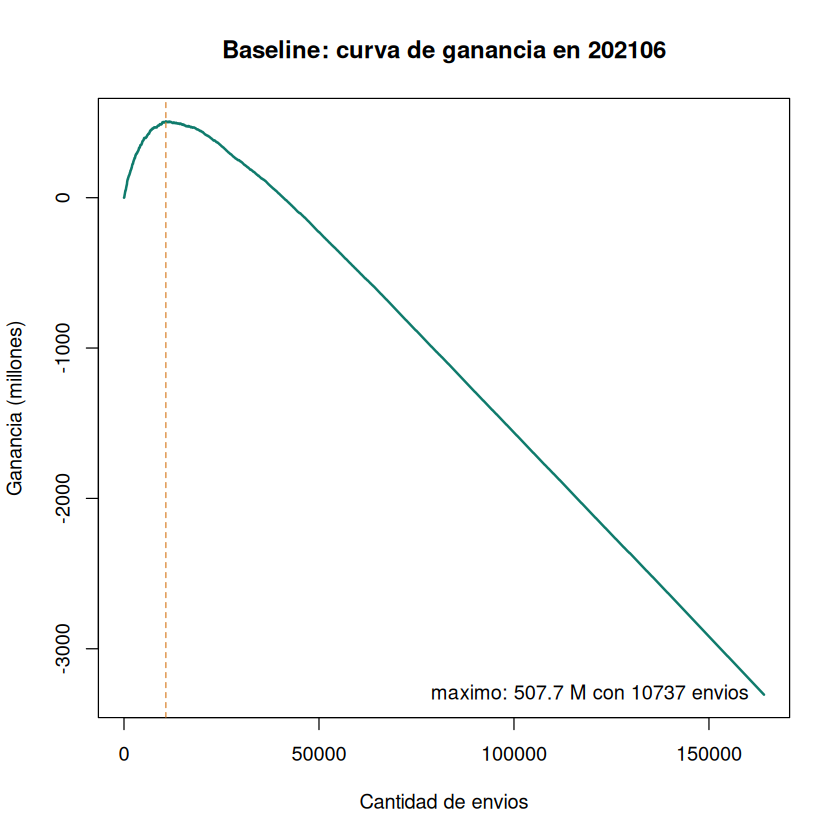

In [44]:
plot(tb_prediccion$pos, tb_prediccion$ganancia_acumulada / 1e6, type = "l", lwd = 2, col = "#0F7B6C",
     xlab = "Cantidad de envios", ylab = "Ganancia (millones)", main = "Baseline: curva de ganancia en 202106")
abline(v = envios_max, lty = 2, col = "#D9822B")
legend("bottomright", legend = paste0("maximo: ", round(ganancia_max / 1e6, 1), " M con ", envios_max, " envios"), bty = "n")

In [45]:
# Tabla de referencia: ganancia en cortes FIJOS (ensamble y por semilla) en 202106
cortes_ref <- sort(unique(c(PARAM$cortes, 10600, 12000)))

# ganancia acumulada de cada semilla (filas = ranking, columnas = semillas)
gan_acum_semilla <- sapply(seq_along(semillas_finales), function(j) {
  cumsum(gan_cliente[order(-prob_semillas[, j])])
})

tabla_ref <- data.table(
  envios            = cortes_ref,
  ensamble_M        = tb_prediccion$ganancia_acumulada[cortes_ref] / 1e6,
  semilla_media_M   = sapply(cortes_ref, function(e) mean(gan_acum_semilla[e, ])) / 1e6,
  semilla_sd_M      = sapply(cortes_ref, function(e) sd(gan_acum_semilla[e, ])) / 1e6,
  semilla_min_M     = sapply(cortes_ref, function(e) min(gan_acum_semilla[e, ])) / 1e6,
  semilla_max_M     = sapply(cortes_ref, function(e) max(gan_acum_semilla[e, ])) / 1e6
)

# rango de envios donde el ensamble queda a menos de 1 desvio por semilla del maximo
sd_ref <- mean(tabla_ref$semilla_sd_M)
max_ens <- max(tb_prediccion$ganancia_acumulada) / 1e6
cat("Maximo del ensamble:", round(max_ens, 2), "M | desvio medio por semilla:", round(sd_ref, 2), "M\n")
cat("Cortes a menos de 1 desvio del maximo:",
    paste(tabla_ref[ensamble_M >= max_ens - sd_ref, envios], collapse = ", "), "\n\n")

print(tabla_ref[, lapply(.SD, round, 2), .SDcols = names(tabla_ref)])
fwrite(tabla_ref, "tabla_referencia_cortes_fijos.csv")

Maximo del ensamble: 507.73 M | desvio medio por semilla: 6.07 M
Cortes a menos de 1 desvio del maximo: 10500, 10600, 11000, 11500, 12000 

    envios ensamble_M semilla_media_M semilla_sd_M semilla_min_M semilla_max_M
     <num>      <num>           <num>        <num>         <num>         <num>
 1:   9000     481.80          478.94         7.46        466.40        491.70
 2:   9500     487.85          485.54         6.40        475.75        494.45
 3:  10000     499.40          490.16         5.71        480.70        497.20
 4:  10500     503.25          494.01         7.08        484.55        505.45
 5:  10600     503.80          494.89         8.62        482.90        509.30
 6:  11000     506.00          496.76         9.10        481.80        511.50
 7:  11500     504.35          497.42         7.67        490.05        510.95
 8:  12000     502.70          498.63         5.54        491.70        509.30
 9:  12500     496.65          496.43         5.33        486.75      